DATASET OVERVIEW
Total samples: 4,237,907
Total subjects: 36
Gesture classes: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7)]

Total recording sessions: 72
Total gesture blocks: 1812

FEATURE EXTRACTION
Feature DataFrame shape: (1812, 12)
Total gesture blocks: 1812


,gesture_block,label,series,class,MAX_ch1,MAX_ch2,MAX_ch3,MAX_ch4,MAX_ch5,MAX_ch6,MAX_ch7,MAX_ch8
0,1,1,1,0,0.000017,0.000029,0.000032,0.000035,0.000016,0.000014,0.000015,0.000014
1,2,1,1,1,0.000016,0.000025,0.000031,0.000021,0.000018,0.000015,0.000013,0.000014
2,3,1,1,0,0.000310,0.000152,0.000211,0.000219,0.000266,0.000396,0.000627,0.000471
3,4,1,1,2,0.000360,0.000147,0.000287,0.000223,0.000187,0.000240,0.000401,0.000259
4,5,1,1,0,0.000455,0.000474,0.000500,0.000421,0.000427,0.000463,0.000453,0.000540



NORMALIZED MAXIMUM FEATURES


,gesture_block,label,series,class,MAX_ch1,MAX_ch2,MAX_ch3,MAX_ch4,MAX_ch5,MAX_ch6,MAX_ch7,MAX_ch8,NMAX_ch1,NMAX_ch2,NMAX_ch3,NMAX_ch4,NMAX_ch5,NMAX_ch6,NMAX_ch7,NMAX_ch8
0,1,1,1,0,0.000017,0.000029,0.000032,0.000035,0.000016,0.000014,0.000015,0.000014,0.100351,0.144950,0.172920,0.162486,0.054070,0.060772,0.097182,0.080955
1,2,1,1,1,0.000016,0.000025,0.000031,0.000021,0.000018,0.000015,0.000013,0.000014,0.092468,0.123766,0.167107,0.097560,0.063458,0.062441,0.082986,0.081992
2,3,1,1,0,0.000310,0.000152,0.000211,0.000219,0.000266,0.000396,0.000627,0.000471,1.824397,0.762614,1.152342,1.030683,0.916100,1.690950,3.968419,2.685257
3,4,1,1,2,0.000360,0.000147,0.000287,0.000223,0.000187,0.000240,0.000401,0.000259,2.113459,0.735396,1.566345,1.049156,0.644400,1.026053,2.538136,1.478215
4,5,1,1,0,0.000455,0.000474,0.000500,0.000421,0.000427,0.000463,0.000453,0.000540,2.671922,2.373072,2.728364,1.980841,1.473592,1.980039,2.867484,3.079687



FILTERED DATASET
Remaining classes: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]
Remaining gesture blocks: 864

Gesture blocks per class:
class
1    144
2    144
3    144
4    144
5    144
6    144
Name: count, dtype: int64

Input shape: (864, 8)
Target shape: (864,)
Number of subjects: 36

TRAIN/TEST SPLIT
Training subjects: 29
Testing subjects: 7
Training gesture blocks: 696
Testing gesture blocks: 168
Training percentage: 80.56%
Testing percentage: 19.44%

Subject overlap: None

Random Forest training completed.

RANDOM FOREST PERFORMANCE - NMAX
Training accuracy: 0.9598 (95.98%)
Testing accuracy:  0.8452 (84.52%)
Macro F1-score:    0.8453

Classification Report:
              precision    recall  f1-score   support

           1       0.97      1.00      0.98        28
           2       0.72      0.82      0.77        28
           3       0.78      0.75      0.76        28
           4       0.86      0.89      0.88        28
           5       

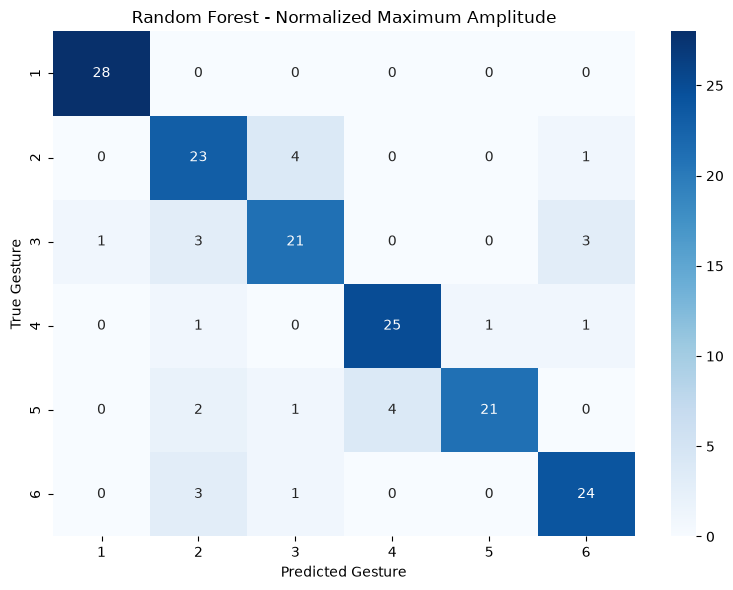


Feature Importance:


,Importance
NMAX_ch6,0.194117
NMAX_ch5,0.160963
NMAX_ch7,0.139463
NMAX_ch4,0.138706
NMAX_ch8,0.105763
NMAX_ch1,0.103861
NMAX_ch3,0.081144
NMAX_ch2,0.075983


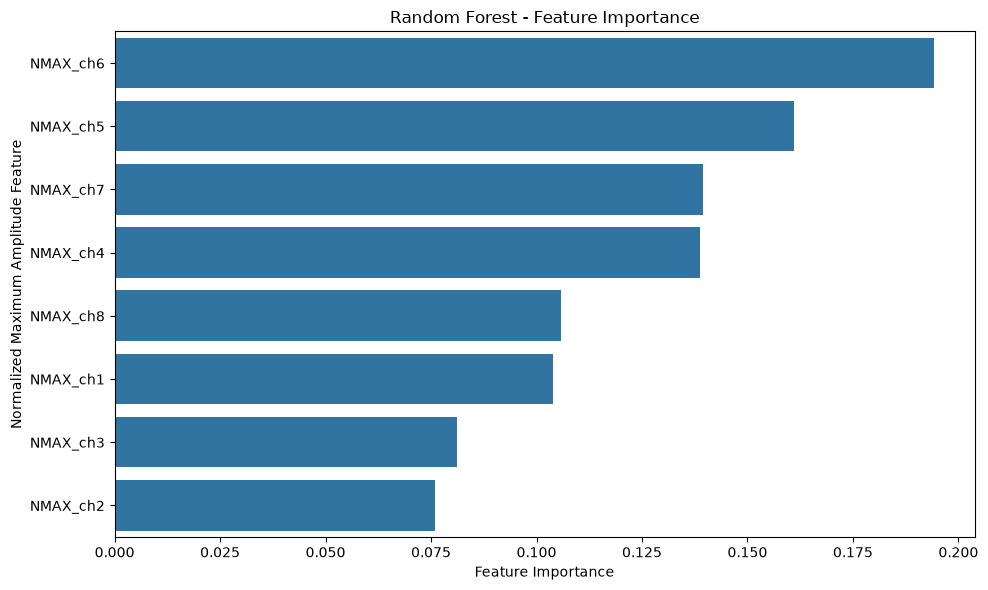

,n_features,train_accuracy,test_accuracy,f1_macro
NMAX,8.0,0.95977,0.845238,0.845343


In [ ]:

# ============================================================
# EMG HAND GESTURE CLASSIFICATION
# RANDOM FOREST - NORMALIZED MAXIMUM AMPLITUDE (NMAX)
# ============================================================

# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.signal import butter, filtfilt
from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)


# ============================================================
# 2. LOAD DATASET
# ============================================================

data = pd.read_csv("Project_Data_EE4C12_S&S_EMG.csv")

channels = [f"channel{i}" for i in range(1, 9)]

print("=" * 60)
print("DATASET OVERVIEW")
print("=" * 60)

print(f"Total samples: {len(data):,}")
print(f"Total subjects: {data['label'].nunique()}")
print(f"Gesture classes: {sorted(data['class'].unique())}")


# ============================================================
# 3. IDENTIFY RECORDING SESSIONS
# ============================================================

# A new session starts when time resets within a subject.
data["new_series"] = (
    data.groupby("label")["time"]
        .diff()
        .fillna(1)
        <= 0
)

# First row of each subject starts a new session.
data["new_series"] = (
    data["new_series"]
    | data.groupby("label").cumcount().eq(0)
)

# Assign session numbers.
data["series"] = (
    data.groupby("label")["new_series"]
        .cumsum()
        .astype(int)
)

data.drop(columns="new_series", inplace=True)

print("\nTotal recording sessions:",
      data.groupby(["label", "series"]).ngroups)


# ============================================================
# 4. IDENTIFY GESTURE BLOCKS
# ============================================================

# A new block begins when:
# - Gesture class changes
# - Recording session changes
# - Subject changes

data["new_gesture"] = (
    data["class"].ne(data["class"].shift())
    | data["series"].ne(data["series"].shift())
    | data["label"].ne(data["label"].shift())
)

data["gesture_block"] = data["new_gesture"].cumsum()

data.drop(columns="new_gesture", inplace=True)

print("Total gesture blocks:",
      data["gesture_block"].nunique())


# ============================================================
# 5. EXTRACT MAXIMUM AMPLITUDE FEATURES
# ============================================================

# EMG filtering parameters
fs = 1000
cutoff = 3
order = 4

# Fourth-order Butterworth low-pass filter
b, a = butter(
    order,
    cutoff / (fs / 2),
    btype="low"
)

feature_rows = []

# Process each gesture block separately.
for block_id, group in data.groupby("gesture_block", sort=False):

    # Extract raw EMG values (samples x 8 channels).
    stroke = group[channels].to_numpy(dtype=float)

    # Rectify EMG signals.
    rectified = np.abs(stroke)

    # Skip blocks that are too short for filtering.
    padlen = 3 * max(len(a), len(b))

    if len(stroke) <= padlen:
        continue

    # Apply low-pass filter to obtain EMG envelope.
    envelope = filtfilt(b, a, rectified, axis=0)

    # Extract maximum envelope amplitude for each channel.
    max_values = np.max(envelope, axis=0)

    # Store extracted features.
    features = {
        "gesture_block": block_id,
        "label": group["label"].iloc[0],
        "series": group["series"].iloc[0],
        "class": group["class"].iloc[0]
    }

    for ch in range(8):
        features[f"MAX_ch{ch+1}"] = max_values[ch]

    feature_rows.append(features)


# Create feature DataFrame.
features_df = pd.DataFrame(feature_rows)

print("\n" + "=" * 60)
print("FEATURE EXTRACTION")
print("=" * 60)

print("Feature DataFrame shape:", features_df.shape)
print("Total gesture blocks:", len(features_df))

display(features_df.head())


# ============================================================
# 6. NORMALIZE MAXIMUM AMPLITUDE FEATURES
# ============================================================

# Normalization follows the same class-balanced approach
# as Normalized Amplitude (NA).
#
# Step 1: Mean MAX per subject, session, class and channel.
# Step 2: Equally weighted mean across gesture classes.
# Step 3: Divide each block's MAX by its reference.

max_cols = [f"MAX_ch{i}" for i in range(1, 9)]

# Step 1: Mean MAX per subject, session and class.
class_means = (
    features_df
    .groupby(["label", "series", "class"])[max_cols]
    .mean()
    .reset_index()
)

# Step 2: Equally weighted mean across gesture classes.
balanced_means = (
    class_means
    .groupby(["label", "series"])[max_cols]
    .mean()
)

# Step 3: Match reference values to each gesture block.
reference = features_df.set_index(["label", "series"]).index

balanced_values = (
    balanced_means
    .reindex(reference)
    .to_numpy()
)

# Step 4: Normalize each channel.
for i, col in enumerate(max_cols):

    features_df[f"NMAX_ch{i+1}"] = (
        features_df[col] /
        (balanced_values[:, i] + 1e-10)
    )

print("\nNORMALIZED MAXIMUM FEATURES")
display(features_df.head())


# ============================================================
# 7. FILTER GESTURE CLASSES
# ============================================================

# Exclude classes 0 and 7.
df_model = features_df[
    ~features_df["class"].isin([0, 7])
].copy()

print("\n" + "=" * 60)
print("FILTERED DATASET")
print("=" * 60)

print("Remaining classes:",
      sorted(df_model["class"].unique()))

print("Remaining gesture blocks:", len(df_model))

print("\nGesture blocks per class:")
print(df_model["class"].value_counts().sort_index())


# ============================================================
# 8. SELECT FEATURES AND TARGET
# ============================================================

# Eight normalized MAX features.
feature_cols = [f"NMAX_ch{i}" for i in range(1, 9)]

X = df_model[feature_cols]
y = df_model["class"]

# Subject identifiers for grouped splitting.
groups = df_model["label"]

print("\nInput shape:", X.shape)
print("Target shape:", y.shape)
print("Number of subjects:", groups.nunique())

# Validate features.
assert not X.isna().any().any(), (
    "Missing feature values detected."
)

assert np.isfinite(X.to_numpy()).all(), (
    "Non-finite feature values detected."
)


# ============================================================
# 9. SUBJECT-BASED TRAIN/TEST SPLIT (80/20)
# ============================================================

# Split by subject rather than individual gesture blocks.
# Both recording sessions from a subject stay together.

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=7,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

# Select training and testing observations.
X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

# Identify subjects in each dataset.
train_subjects = set(groups.iloc[train_idx])
test_subjects = set(groups.iloc[test_idx])

print("\n" + "=" * 60)
print("TRAIN/TEST SPLIT")
print("=" * 60)

print("Training subjects:", len(train_subjects))
print("Testing subjects:", len(test_subjects))

print("Training gesture blocks:", len(X_train))
print("Testing gesture blocks:", len(X_test))

print(f"Training percentage: {len(X_train)/len(X)*100:.2f}%")
print(f"Testing percentage: {len(X_test)/len(X)*100:.2f}%")

# Verify no subject overlap.
assert train_subjects.isdisjoint(test_subjects), (
    "ERROR: Subject overlap detected!"
)

# Verify all classes occur in both datasets.
expected_classes = set(y.unique())

assert set(y_train.unique()) == expected_classes
assert set(y_test.unique()) == expected_classes

print("\nSubject overlap: None")


# ============================================================
# 10. TRAIN RANDOM FOREST
# ============================================================

# rf_model = RandomForestClassifier(
#     n_estimators=100,
#     random_state=42,
#     n_jobs=-1
# )

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=5,
    max_features="sqrt",
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("\nRandom Forest training completed.")


# ============================================================
# 11. MAKE PREDICTIONS
# ============================================================

y_train_pred = rf_model.predict(X_train)
y_test_pred = rf_model.predict(X_test)


# ============================================================
# 12. MODEL EVALUATION
# ============================================================

train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

macro_f1 = f1_score(
    y_test,
    y_test_pred,
    average="macro"
)

print("\n" + "=" * 60)
print("RANDOM FOREST PERFORMANCE - NMAX")
print("=" * 60)

print(f"Training accuracy: {train_accuracy:.4f} "
      f"({train_accuracy*100:.2f}%)")

print(f"Testing accuracy:  {test_accuracy:.4f} "
      f"({test_accuracy*100:.2f}%)")

print(f"Macro F1-score:    {macro_f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred))


# Store model results.
model_results = {}

model_results["NMAX"] = {
    "n_features": len(feature_cols),
    "train_accuracy": train_accuracy,
    "test_accuracy": test_accuracy,
    "f1_macro": macro_f1
}


# ============================================================
# 13. CONFUSION MATRIX
# ============================================================

classes = sorted(y.unique())

cm = confusion_matrix(
    y_test,
    y_test_pred,
    labels=classes
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes
)

plt.title("Random Forest - Normalized Maximum Amplitude")
plt.xlabel("Predicted Gesture")
plt.ylabel("True Gesture")

plt.tight_layout()
plt.show()


# ============================================================
# 14. FEATURE IMPORTANCE
# ============================================================

importance = pd.Series(
    rf_model.feature_importances_,
    index=feature_cols
).sort_values(ascending=False)

print("\nFeature Importance:")
display(importance.to_frame("Importance"))

plt.figure(figsize=(10, 6))

sns.barplot(
    x=importance.values,
    y=importance.index
)

plt.title("Random Forest - Feature Importance")
plt.xlabel("Feature Importance")
plt.ylabel("Normalized Maximum Amplitude Feature")

plt.tight_layout()
plt.show()


# ============================================================
# 15. DISPLAY MODEL RESULTS
# ============================================================

results_df = pd.DataFrame(model_results).T

display(results_df)
